# 岭回归

In [34]:
# 导入库
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge, LinearRegression, Lasso
from sklearn.model_selection import train_test_split as TTS
from sklearn.datasets import fetch_california_housing as fch
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

In [7]:
housevalue = fch()
X = pd.DataFrame(housevalue.data) # 特征-房屋特征
y = housevalue.target # 标签-房价

X.columns = [
    "住户收入中位数", "房屋使用年代中位数", "平均房间数目", "平均卧室数目", "街区人口", "平均入住率", "街区的经度", "街区的维度"
]

In [8]:
X.head()

,住户收入中位数,房屋使用年代中位数,平均房间数目,平均卧室数目,街区人口,平均入住率,街区的经度,街区的维度
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [9]:
# 训练集、测试集划分
Xtrain, Xtest, Ytrain, Ytest = TTS(X, y, test_size=0.3, random_state=420)

In [10]:
Xtrain

,住户收入中位数,房屋使用年代中位数,平均房间数目,平均卧室数目,街区人口,平均入住率,街区的经度,街区的维度
17073,4.1776,35.0,4.425172,1.030683,5380.0,3.368817,37.48,-122.19
16956,5.3261,38.0,6.267516,1.089172,429.0,2.732484,37.53,-122.30
20012,1.9439,26.0,5.768977,1.141914,891.0,2.940594,36.02,-119.08
13072,2.5000,22.0,4.916000,1.012000,733.0,2.932000,38.57,-121.31
8457,3.8250,34.0,5.036765,1.098039,1134.0,2.779412,33.91,-118.35
...,...,...,...,...,...,...,...,...
10394,4.7981,16.0,6.408537,1.067073,1003.0,3.057927,33.54,-117.67
1209,2.3816,16.0,6.055954,1.120516,1516.0,2.175036,38.15,-120.46
14254,1.7500,25.0,3.912500,1.029167,1003.0,4.179167,32.71,-117.10
19059,3.5647,33.0,5.423358,1.058394,781.0,2.850365,38.22,-122.49


In [11]:
for i in [Xtrain, Xtest]:
    i.index = range(i.shape[0])

In [13]:
Xtrain.head()

,住户收入中位数,房屋使用年代中位数,平均房间数目,平均卧室数目,街区人口,平均入住率,街区的经度,街区的维度
0,4.1776,35.0,4.425172,1.030683,5380.0,3.368817,37.48,-122.19
1,5.3261,38.0,6.267516,1.089172,429.0,2.732484,37.53,-122.30
2,1.9439,26.0,5.768977,1.141914,891.0,2.940594,36.02,-119.08
3,2.5000,22.0,4.916000,1.012000,733.0,2.932000,38.57,-121.31
4,3.8250,34.0,5.036765,1.098039,1134.0,2.779412,33.91,-118.35


In [14]:
# 岭回归建模
# 加利佛尼亚房价数据集中应该不是多重共线性问题
reg = Ridge(alpha=1).fit(Xtrain, Ytrain)
reg.score(Xtest, Ytest)

0.6043610352312279

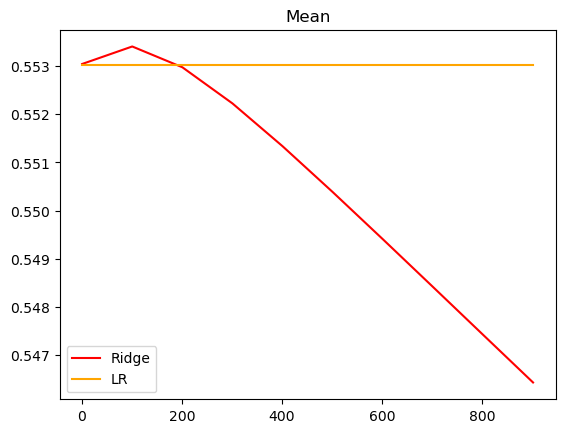

In [16]:
# 交叉验证情况下，岭回归和线性回归的对比
alpharange = np.arange(1, 1001, 100)
ridge, lr = [],[]
for alpha in alpharange:
    reg = Ridge(alpha=alpha)
    linear = LinearRegression()
    regs = cross_val_score(reg, X, y, cv=5, scoring="r2").mean()
    linears = cross_val_score(linear, X, y, cv=5, scoring="r2").mean()
    ridge.append(regs)
    lr.append(linears)
    
plt.plot(alpharange, ridge, color="red", label="Ridge")
plt.plot(alpharange, lr, color="orange", label="LR")
plt.title("Mean")
plt.legend()
plt.show()
    

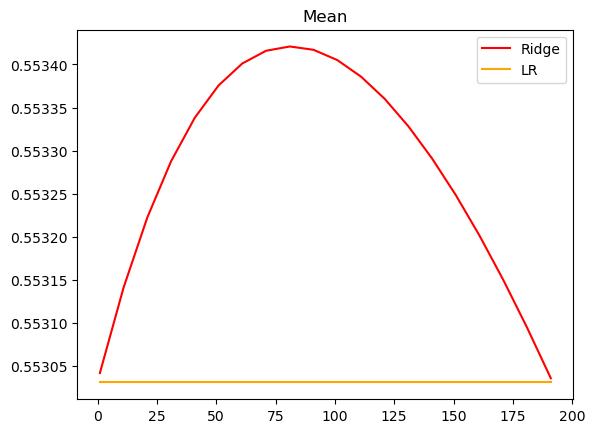

In [18]:
# 精细调参
alpharange = np.arange(1, 201, 10)
ridge, lr = [],[]
for alpha in alpharange:
    reg = Ridge(alpha=alpha)
    linear = LinearRegression()
    regs = cross_val_score(reg, X, y, cv=5, scoring="r2").mean()
    linears = cross_val_score(linear, X, y, cv=5, scoring="r2").mean()
    ridge.append(regs)
    lr.append(linears)
    
plt.plot(alpharange, ridge, color="red", label="Ridge")
plt.plot(alpharange, lr, color="orange", label="LR")
plt.title("Mean")
plt.legend()
plt.show()
    

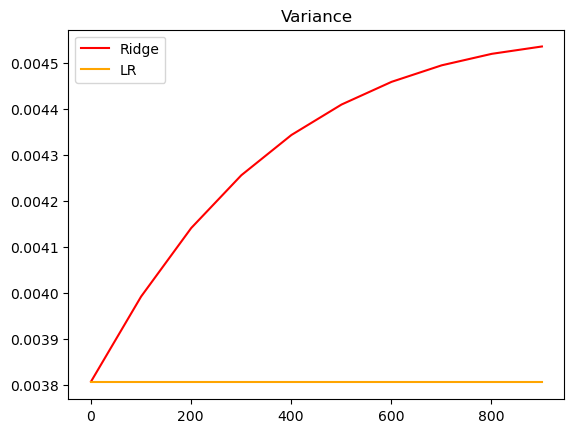

In [20]:
# 模型方差如何变化
alpharange = np.arange(1, 1001, 100)
ridge, lr = [],[]
for alpha in alpharange:
    reg = Ridge(alpha=alpha)
    linear = LinearRegression()
    varR = cross_val_score(reg, X, y, cv=5, scoring="r2").var()
    varLR = cross_val_score(linear, X, y, cv=5, scoring="r2").var()
    ridge.append(varR)
    lr.append(varLR)
    
plt.plot(alpharange, ridge, color="red", label="Ridge")
plt.plot(alpharange, lr, color="orange", label="LR")
plt.title("Variance")
plt.legend()
plt.show()
    

In [22]:
# 交叉验证选择Alpha参数
# 导入库
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge, LinearRegression, Lasso
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split as TTS
from sklearn.datasets import fetch_california_housing as fch
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

housevalue = fch()
X = pd.DataFrame(housevalue.data) # 特征-房屋特征
y = housevalue.target # 标签-房价

X.columns = [
    "住户收入中位数", "房屋使用年代中位数", "平均房间数目", "平均卧室数目", "街区人口", "平均入住率", "街区的经度", "街区的维度"
]

In [24]:
Ridge_ = RidgeCV(alphas=np.arange(1, 1001, 100)
                 ,store_cv_values=True).fit(X, y)

In [25]:
# 无关交叉验证的岭回归结果
Ridge_.score(X, y)

0.6060251767338396

In [28]:
Ridge_.cv_values_.shape

(20640, 10)

In [27]:
# 调用所有交叉验证的结果
# 每一行代表一个留一交叉验证的结果，20639训练集，1测试集
# 每一列代表每一个Alpha下的交叉验证结果
Ridge_.cv_values_

array([[0.1557472 , 0.16301246, 0.16892723, ..., 0.18881663, 0.19182353,
        0.19466385],
       [0.15334566, 0.13922075, 0.12849014, ..., 0.09744906, 0.09344092,
        0.08981868],
       [0.02429857, 0.03043271, 0.03543001, ..., 0.04971514, 0.05126165,
        0.05253834],
       ...,
       [0.56545783, 0.5454654 , 0.52655917, ..., 0.44532597, 0.43130136,
        0.41790336],
       [0.27883123, 0.2692305 , 0.25944481, ..., 0.21328675, 0.20497018,
        0.19698274],
       [0.14313527, 0.13967826, 0.13511341, ..., 0.1078647 , 0.10251737,
        0.0973334 ]])

In [29]:
# 进行平均后可以查看每个正则化系数取值下的交叉验证结果
Ridge_.cv_values_.mean(axis=0)

array([0.52823795, 0.52787439, 0.52807763, 0.52855759, 0.52917958,
       0.52987689, 0.53061486, 0.53137481, 0.53214638, 0.53292369])

In [30]:
# 查看被选择出的最佳正则化系数
Ridge_.alpha_

101

In [32]:
Ridge_ = RidgeCV(alphas=np.arange(1, 1001, 100)
                 ,store_cv_values=False
                 ,cv=5).fit(X, y)

In [33]:
Ridge_.cv_values_

AttributeError: 'RidgeCV' object has no attribute 'cv_values_'

# Lasso回归

In [35]:
# 导入库
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge, LinearRegression, Lasso
from sklearn.model_selection import train_test_split as TTS
from sklearn.datasets import fetch_california_housing as fch
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

housevalue = fch()
X = pd.DataFrame(housevalue.data) # 特征-房屋特征
y = housevalue.target # 标签-房价

X.columns = [
    "住户收入中位数", "房屋使用年代中位数", "平均房间数目", "平均卧室数目", "街区人口", "平均入住率", "街区的经度", "街区的维度"
]
X.head()

,住户收入中位数,房屋使用年代中位数,平均房间数目,平均卧室数目,街区人口,平均入住率,街区的经度,街区的维度
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [36]:
# 训练集测试集的划分
Xtrain, Xtest, Ytrain, Ytest = TTS(X, y, test_size=0.3, random_state=420)

In [37]:
# 修正索引
for i in [Xtrain, Xtest]:
    i.index = range(i.shape[0])

In [39]:
# 线性回归进行拟合
reg = LinearRegression().fit(Xtrain, Ytrain)
(reg.coef_ * 100).tolist()

[43.73589305968399,
 1.0211268294494025,
 -10.780721617317605,
 62.643382753637745,
 5.216125353526433e-05,
 -0.33485096463335545,
 -41.30959378947707,
 -42.621095362084795]

In [40]:
# 岭回归进行拟合
Ridge_ = Ridge(alpha=0).fit(Xtrain, Ytrain)
(Ridge_.coef_ * 100).tolist()

[43.73589305968394,
 1.0211268294494067,
 -10.780721617317557,
 62.64338275363727,
 5.2161253532676486e-05,
 -0.3348509646333573,
 -41.30959378947717,
 -42.62109536208473]

In [41]:
# Lasso回归进行拟合
lasso_ = Lasso(alpha=0).fit(Xtrain, Ytrain)
(lasso_.coef_ * 100).tolist()

/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py:1151: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:628: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.770e+03, tolerance: 1.917e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinat

[43.73589305968436,
 1.0211268294494429,
 -10.780721617317985,
 62.64338275363867,
 5.2161253532799685e-05,
 -0.3348509646333631,
 -41.309593789475144,
 -42.62109536208259]

In [42]:
# 岭回归进行拟合(alpha=0.1)
Ridge_ = Ridge(alpha=0.1).fit(Xtrain, Ytrain)
(Ridge_.coef_ * 100).tolist()

[43.734534807869444,
 1.0211508518425598,
 -10.778109335481762,
 62.62978997580397,
 5.2255520319355066e-05,
 -0.3348478363544358,
 -41.30937006538795,
 -42.62068050768494]

In [43]:
# Lasso回归进行拟合(alpha=0.1)
lasso_ = Lasso(alpha=0.1).fit(Xtrain, Ytrain)
(lasso_.coef_ * 100).tolist()

[39.08851438329681,
 1.6054695654279847,
 -0.0,
 0.0,
 0.0023777014839091257,
 -0.3050186895638111,
 -10.771509301655492,
 -9.294344477957992]

In [ ]:
# 线性回归结果
# [43.73589305968399,
#  1.0211268294494025,
#  -10.780721617317605,
#  62.643382753637745,
#  5.216125353526433e-05,
#  -0.33485096463335545,
#  -41.30959378947707,
#  -42.621095362084795]

In [44]:
# 岭回归进行拟合(alpha=10**4)
Ridge_ = Ridge(alpha=10**4).fit(Xtrain, Ytrain)
(Ridge_.coef_ * 100).tolist()

[34.62081517607692,
 1.519617086923868,
 0.39686105292102364,
 0.9151812510354776,
 0.002173923801224839,
 -0.34768660148101005,
 -14.736963474215312,
 -13.435576102526966]

In [45]:
# Lasso回归进行拟合(alpha=10**4)
# 10**4对于Lasso来说是一个过于大的取值
lasso_ = Lasso(alpha=10**4).fit(Xtrain, Ytrain)
(lasso_.coef_ * 100).tolist()

[0.0, 0.0, 0.0, -0.0, -0.0, -0.0, -0.0, -0.0]

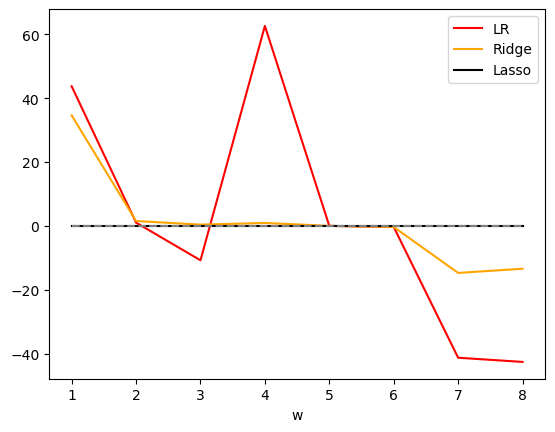

In [49]:
# 系数绘图

plt.plot(range(1, 9), (reg.coef_*100).tolist(), color="red", label="LR")
plt.plot(range(1, 9), (Ridge_.coef_*100).tolist(), color="orange", label="Ridge")
plt.plot(range(1, 9), (lasso_.coef_*100).tolist(), color="k", label="Lasso")
plt.plot(range(1, 9), [0]*8, color="grey", linestyle="--")
plt.xlabel("w")
plt.legend()
plt.show()

In [51]:
# 交叉验证下Lasso的正则化参数选择
from sklearn.linear_model import LassoCV

# 自己建立Lasso进行alpha选择
alpharange = np.logspace(-10, -2, 200, base=10) # 以10为底的指数函数，10^-10~10^-2

alpharange.shape


(200,)

In [52]:
Xtrain.head()

,住户收入中位数,房屋使用年代中位数,平均房间数目,平均卧室数目,街区人口,平均入住率,街区的经度,街区的维度
0,4.1776,35.0,4.425172,1.030683,5380.0,3.368817,37.48,-122.19
1,5.3261,38.0,6.267516,1.089172,429.0,2.732484,37.53,-122.30
2,1.9439,26.0,5.768977,1.141914,891.0,2.940594,36.02,-119.08
3,2.5000,22.0,4.916000,1.012000,733.0,2.932000,38.57,-121.31
4,3.8250,34.0,5.036765,1.098039,1134.0,2.779412,33.91,-118.35


In [53]:
lasso_ = LassoCV(alphas=alpharange
                 ,cv=5).fit(Xtrain, Ytrain)

In [54]:
# 查看被选择出来的最佳正则化
lasso_.alpha_

0.0020729217795953697

In [56]:
lasso_.mse_path_.shape # 返回的是每个alpha下的五折交叉验证结果

(200, 5)

In [55]:
lasso_.mse_path_

array([[0.52454913, 0.49856261, 0.55984312, 0.50526576, 0.55262557],
       [0.52361933, 0.49748809, 0.55887637, 0.50429373, 0.55283734],
       [0.52281927, 0.49655113, 0.55803797, 0.5034594 , 0.55320522],
       [0.52213811, 0.49574741, 0.55731858, 0.50274517, 0.55367515],
       [0.52155715, 0.49505688, 0.55669995, 0.50213252, 0.55421553],
       [0.52106069, 0.49446226, 0.55616707, 0.50160604, 0.55480104],
       [0.5206358 , 0.49394903, 0.55570702, 0.50115266, 0.55541214],
       [0.52027135, 0.49350539, 0.55530895, 0.50076146, 0.55603333],
       [0.51995825, 0.49312085, 0.5549639 , 0.50042318, 0.55665306],
       [0.5196886 , 0.49278705, 0.55466406, 0.50013007, 0.55726225],
       [0.51945602, 0.49249647, 0.55440306, 0.49987554, 0.55785451],
       [0.51925489, 0.49224316, 0.55417527, 0.49965404, 0.55842496],
       [0.51908068, 0.49202169, 0.55397615, 0.49946088, 0.55897049],
       [0.51892938, 0.49182782, 0.55380162, 0.49929206, 0.55948886],
       [0.51879778, 0.49165759, 0.

In [57]:
lasso_.mse_path_.mean(axis=1)

# 在岭回归中，是留一交叉验证，因此交叉验证结果返回的是，每一个样本在每个alpha下的交叉验证结果
# 因此要求每个alpha下的交叉验证均值，就是axis=0，跨行求均值
# 而在这里，返回的是，每一个alpha取值下，每一折交叉验证的结果
# 因此要求每个alpha下的交叉验证均值，就是axis=1，跨列求均值

array([0.52816924, 0.52742297, 0.5268146 , 0.52632488, 0.52593241,
       0.52561942, 0.52537133, 0.5251761 , 0.52502385, 0.52490641,
       0.52481712, 0.52475046, 0.52470198, 0.52466795, 0.52464541,
       0.52463188, 0.5246254 , 0.52462436, 0.52462744, 0.52463361,
       0.52464201, 0.52465199, 0.52466301, 0.52467466, 0.5246866 ,
       0.5246986 , 0.52471046, 0.52472203, 0.5247332 , 0.52474392,
       0.52475413, 0.52476379, 0.52477291, 0.52478147, 0.52478949,
       0.52479697, 0.52480393, 0.52481039, 0.52481639, 0.52482193,
       0.52482706, 0.52483179, 0.52483615, 0.52484016, 0.52484385,
       0.52484725, 0.52485036, 0.52485322, 0.52485584, 0.52485824,
       0.52486044, 0.52486246, 0.5248643 , 0.52486599, 0.52486753,
       0.52486895, 0.52487024, 0.52487141, 0.52487249, 0.52487348,
       0.52487437, 0.52487519, 0.52487594, 0.52487663, 0.52487725,
       0.52487782, 0.52487834, 0.52487882, 0.52487925, 0.52487965,
       0.52488001, 0.52488033, 0.52488063, 0.52488091, 0.52488

In [58]:
# 最佳正则化系数下获得的模型系数结果
lasso_.coef_

array([ 4.29867301e-01,  1.03623683e-02, -9.32648616e-02,  5.51755252e-01,
        1.14732262e-06, -3.31941716e-03, -4.10451223e-01, -4.22410330e-01])

In [59]:
lasso_.score(Xtest, Ytest)

0.6038982670571436

In [60]:
reg = LinearRegression().fit(Xtrain, Ytrain)
reg.score(Xtest, Ytest)

0.6043668160178813

In [74]:
ls_ = LassoCV(eps=0.0001
              ,n_alphas=300
              ,cv=5).fit(Xtrain, Ytrain)
# ls_.alphas_
ls_.alpha_

0.002940597369832646

In [75]:
ls_.score(Xtest, Ytest)

0.6036135609816558

In [76]:
ls_.coef_

array([ 4.26722427e-01,  1.04253992e-02, -8.71648975e-02,  5.20444027e-01,
        1.40841579e-06, -3.30718197e-03, -4.09361522e-01, -4.20836139e-01])

# 弹性网模型

In [78]:
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import ElasticNetCV

reg_EN = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=420).fit(Xtrain, Ytrain)

In [79]:
reg_EN.alpha

1.0

In [80]:
reg_EN.l1_ratio

0.5

In [81]:
reg_EN.coef_

array([ 2.53207411e-01,  1.18992269e-02,  0.00000000e+00, -0.00000000e+00,
        1.41828570e-05, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00])

In [82]:
reg_EN.intercept_

0.7217473009625777